# Exploração de segmentação por limiarização

Nesta etapa, transformamos as intensidades do volume MRI em uma máscara binária para observar quais regiões ficariam acima de diferentes limiares. A máscara serve para experimentar: ainda não aplicaremos operações morfolêgicas, não salvaremos arquivos processados e não faremos reconstrução 3D.

## Ideia matemática

Dado um limiar `T`, a máscara ? definida por `M(z, y, x) = 1` se `I(z, y, x) > T` e `M(z, y, x) = 0` caso contrário. `I` ? a intensidade do voxel, e `M` indica apenas se ele passou pelo critério. A fração de voxels selecionados ? `número de voxels com I > T / número total de voxels`.

O método de Otsu escolhe automaticamente um limiar usando o histograma. ? um método matemático, não um reconhecedor de anatomia: pode incluir regiões de intensidade alta e excluir regiões de intensidade menor.

Os valores DICOM são intensidades digitais MRI, não unidades calibradas como HU. Os limiares manuais 50, 100 e 150 são experimentais e **não** devem ser apresentados como valores clênicos. O Otsu do volume também pode produzir resultado diferente do Otsu de um único corte.

## Bibliotecas utilizadas

- **OpenCV** (`cv2.threshold`): calcula Otsu em imagens `uint16` e cria máscaras binárias 2D/3D.
- **NumPy**, **OpenCV** e **Matplotlib**: calculam proporções e mostram as distribuições e máscaras.

## 1. Carregar a série original

O carregador reúne as imagens DICOM da série `skull` e ordena os cortes pelas posições físicas dos metadados, não pela ordem alfabética dos nomes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import cv2
import sys

current_dir = Path.cwd().resolve()
search_dirs = [current_dir, *current_dir.parents]
search_dirs.extend(parent / "reconstrucao-cranio" for parent in search_dirs.copy())
project_root = next(
    (folder for folder in search_dirs if (folder / "data" / "skull").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Não encontrei data/skull. "
        f"Diretório de trabalho atual do Jupyter: {current_dir}."
    )

src_path = str(project_root / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)
from leitura import ler_dicom_volume

data_dir = project_root / "data" / "skull" / "0051" / "0051"
volume, voxel_spacing_zyx, image_files = ler_dicom_volume(data_dir)
if volume.ndim != 3 or volume.shape[0] != len(image_files):
    raise ValueError(
        f"Volume DICOM inesperado: dimensões {volume.shape}, tipo {volume.dtype}."
    )

slice_index = volume.shape[0] // 2
central_slice = volume[slice_index]

def criar_mascara_volume(dados: np.ndarray, limiar: float) -> np.ndarray:
    _, mascara_plana = cv2.threshold(
        dados.reshape(-1, 1), float(limiar), 1, cv2.THRESH_BINARY
    )
    return mascara_plana.reshape(dados.shape).astype(bool)

print(f"Pasta do projeto: {project_root}")
print(f"Volume MRI: {volume.shape}, tipo {volume.dtype}")
print(f"Espaçamento DICOM (z, y, x), em mm: {voxel_spacing_zyx}")
print(f"Corte central para visualização: {slice_index + 1}")

Pasta do projeto: C:\Users\amart\Documents\pdi\Reconstrução 3D de Imagens Médicas\reconstrucao-cranio
Volume MRI: (108, 512, 512), tipo uint16
Espaçamento DICOM (z, y, x), em mm: (1.5, 0.4785156, 0.4785156)
Corte central para visualização: 55


## 2. Calcular e comparar limiares

Calculamos Otsu no volume e, separadamente, no corte central para observar se o resultado depende do conjunto de pixels analisado. Também examinamos os limiares manuais 50, 100 e 150, escolhidos para comparação com base na distribuição de intensidade observada. São pontos exploratérios, não uma regra de segmentação anatômica.

A tabela calcula quantos voxels passam em cada limiar e qual parte do volume eles representam. Um limiar mais alto sempre seleciona a mesma quantidade ou menos voxels que um limiar mais baixo.

In [2]:
otsu_volume, _ = cv2.threshold(
    volume.reshape(-1, 1), 0, 1, cv2.THRESH_BINARY | cv2.THRESH_OTSU
)
otsu_volume = float(otsu_volume)
otsu_slice, _ = cv2.threshold(
    central_slice, 0, 1, cv2.THRESH_BINARY | cv2.THRESH_OTSU
)
otsu_slice = float(otsu_slice)
manual_thresholds = (50, 100, 150)

print(f"Otsu no volume: {otsu_volume:g}")
print(f"Otsu no corte central: {otsu_slice:g}")
print("\nLimiar | Voxels selecionados | Fração do volume")
for threshold in (otsu_volume, *manual_thresholds):
    voxel_count = int(np.count_nonzero(criar_mascara_volume(volume, threshold)))
    fraction = voxel_count / volume.size
    print(f"{threshold:7.1f} | {voxel_count:19,d} | {fraction:15.2%}")

if not (0 <= otsu_volume <= volume.max()):
    raise ValueError(f"O limiar de Otsu está fora da faixa do volume: {otsu_volume}.")

Otsu no volume: 623
Otsu no corte central: 614

Limiar | Voxels selecionados | Fração do volume
  623.0 |           9,530,659 |          33.66%
   50.0 |          12,278,535 |          43.37%
  100.0 |          11,870,410 |          41.93%
  150.0 |          11,567,634 |          40.86%


## 3. Relacionar o histograma com o corte

O histograma mostra quantos pixels do corte central pertencem a cada faixa de intensidade. As linhas verticais marcam o Otsu do volume e os limiares manuais. O histograma pode ter vários grupos sobrepostos, por isso uma única linha nem sempre separa perfeitamente os tecidos.

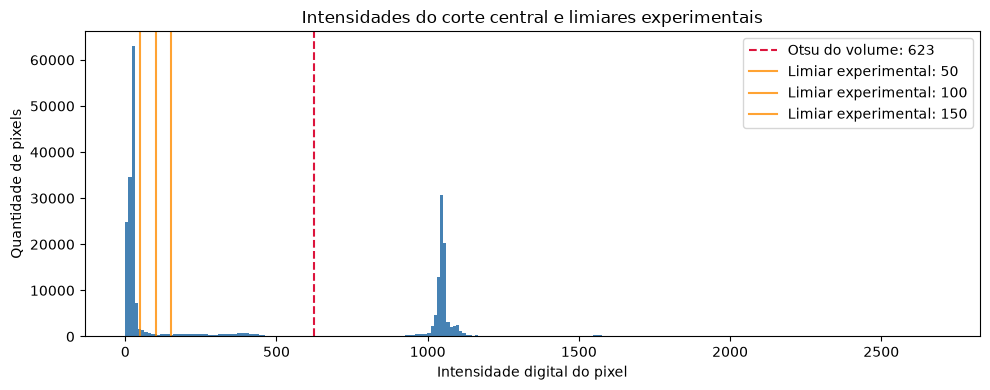

In [3]:
plt.figure(figsize=(10, 4))
plt.hist(central_slice.ravel(), bins=256, color="steelblue")
plt.axvline(otsu_volume, color="crimson", linestyle="--", label=f"Otsu do volume: {otsu_volume:g}")
for threshold in manual_thresholds:
    plt.axvline(threshold, color="darkorange", alpha=0.8, label=f"Limiar experimental: {threshold}")
plt.title("Intensidades do corte central e limiares experimentais")
plt.xlabel("Intensidade digital do pixel")
plt.ylabel("Quantidade de pixels")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Inspecionar o resultado binário

A comparação lado a lado permite ver como a posição do limiar altera as regiões selecionadas. O painel original e todas as máscaras usam o mesmo corte. Em cada máscara, branco significa que a intensidade ultrapassou o limiar e preto significa que não ultrapassou.

Observe como as regiões brilhantes e os detalhes mudam. Isso ? avaliação visual exploratéria: sem anotações de referência e sem intensidades calibradas, não permite declarar que um limiar segmenta corretamente a anatomia.

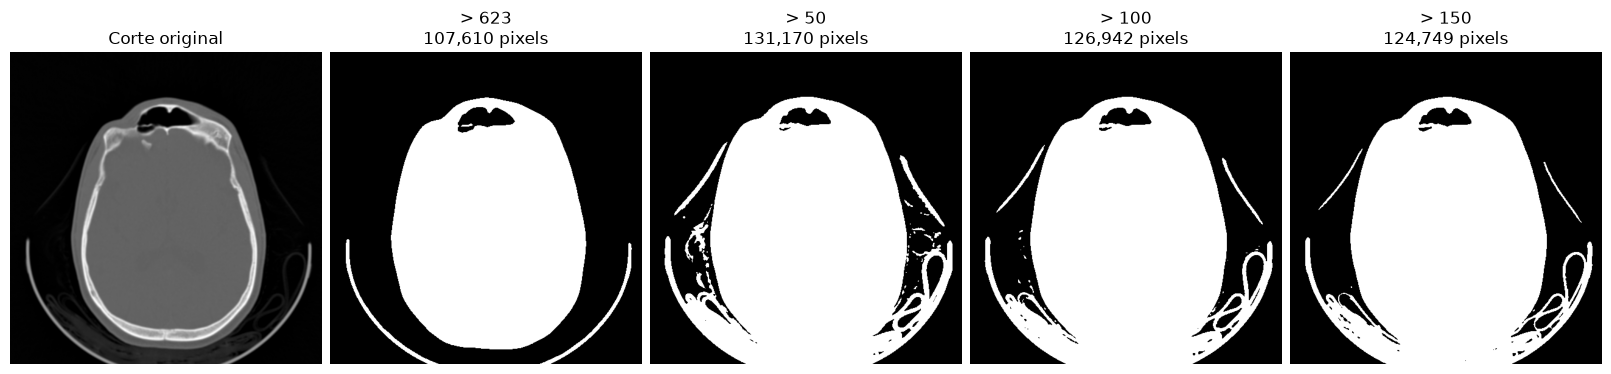

In [4]:
thresholds_to_compare = (otsu_volume, *manual_thresholds)
fig, axes = plt.subplots(1, len(thresholds_to_compare) + 1, figsize=(16, 4), layout="constrained")
axes[0].imshow(central_slice, cmap="gray")
axes[0].set_title("Corte original")
axes[0].axis("off")

for ax, threshold in zip(axes[1:], thresholds_to_compare):
    _, mask_2d = cv2.threshold(central_slice, float(threshold), 1, cv2.THRESH_BINARY)
    mask_2d = mask_2d.astype(bool)
    ax.imshow(mask_2d, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"> {threshold:g}\n{np.count_nonzero(mask_2d):,} pixels")
    ax.axis("off")

plt.show()

## 5. Criar uma máscara exploratória para o volume

Construímos uma máscara 3D com o Otsu calculado no volume inteiro, e outra com o limiar experimental 100, para comparar as mesmas posições anatômicas entre o primeiro, o central e o último corte. Os valores da máscara são booleanos (`True`/`False`), não intensidades tomográficas. As máscaras continuam apenas em memória.

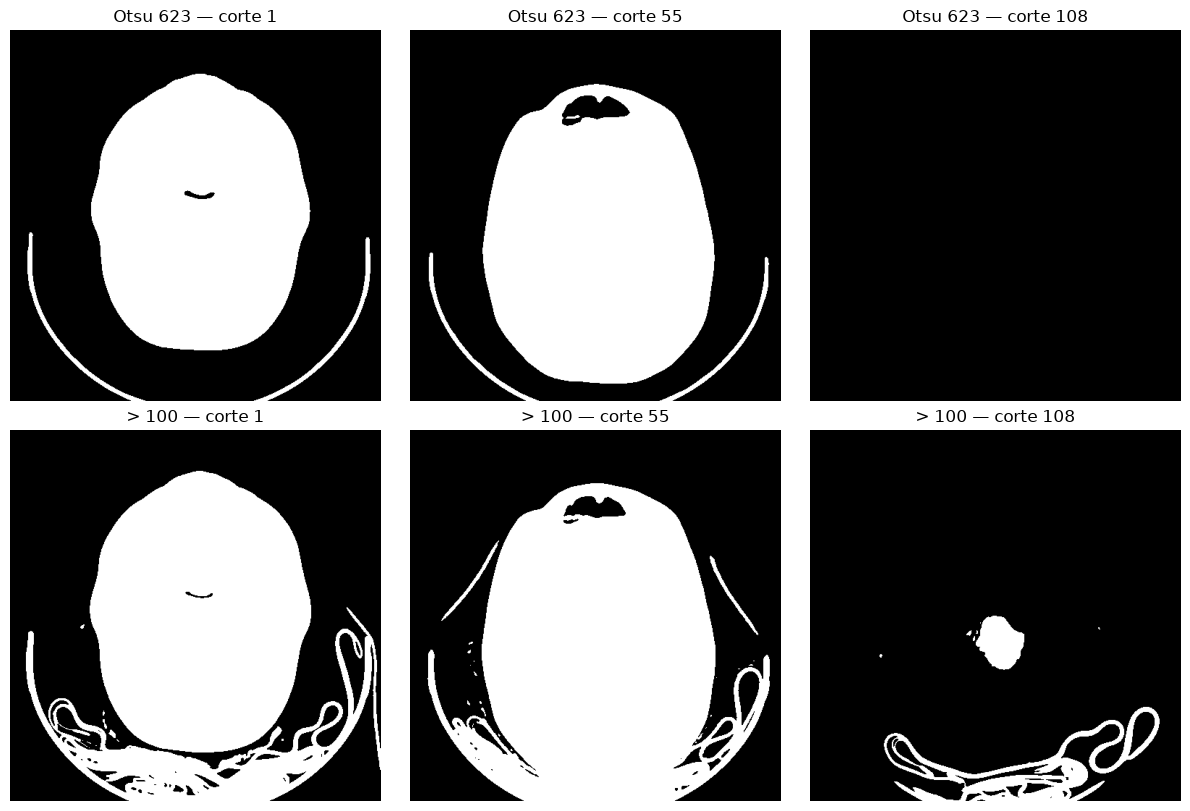

Máscara de Otsu: forma (108, 512, 512), tipo bool
Máscara experimental: forma (108, 512, 512), tipo bool
Voxels selecionados por Otsu: 9,530,659 (33.66%)
Voxels selecionados por 100: 11,870,410 (41.93%)


In [5]:
experimental_threshold = 100
mask_otsu_3d = criar_mascara_volume(volume, otsu_volume)
mask_experimental_3d = criar_mascara_volume(volume, experimental_threshold)
slice_indices = (0, slice_index, len(volume) - 1)

fig, axes = plt.subplots(2, 3, figsize=(12, 8), layout="constrained")
for column, index in enumerate(slice_indices):
    axes[0, column].imshow(mask_otsu_3d[index], cmap="gray", vmin=0, vmax=1)
    axes[0, column].set_title(f"Otsu {otsu_volume:g} — corte {index + 1}")
    axes[0, column].axis("off")

    axes[1, column].imshow(mask_experimental_3d[index], cmap="gray", vmin=0, vmax=1)
    axes[1, column].set_title(f"> {experimental_threshold} — corte {index + 1}")
    axes[1, column].axis("off")

plt.show()
print(f"Máscara de Otsu: forma {mask_otsu_3d.shape}, tipo {mask_otsu_3d.dtype}")
print(f"Máscara experimental: forma {mask_experimental_3d.shape}, tipo {mask_experimental_3d.dtype}")
print(f"Voxels selecionados por Otsu: {np.count_nonzero(mask_otsu_3d):,} ({mask_otsu_3d.mean():.2%})")
print(f"Voxels selecionados por {experimental_threshold}: {np.count_nonzero(mask_experimental_3d):,} ({mask_experimental_3d.mean():.2%})")

if mask_otsu_3d.shape != volume.shape or mask_experimental_3d.shape != volume.shape:
    raise ValueError("A máscara não corresponde às dimensões do volume original.")

## Interpretar antes de avançar

Compare os valores de Otsu, as frações da tabela e as regiões brancas nas figuras. Um limiar global pode incluir regiões que não são de interesse e excluir estruturas com intensidade menor. A tabela quantifica voxels selecionados, mas não mede acerto anatômico.

Neste exercício não fazemos operações morfolêgicas, não removemos componentes, não salvamos máscaras e não reconstruímos uma superfície. As intensidades são digitais, não unidades clênicas calibradas; os resultados são exploratérios e não constituem avaliação clênica.